# Catalan's constant $G$: historical constructions and new result

Exact rational approximants, sampled up to index 500.
$\delta_N=-1-\log|\alpha-p_N/q_N|/\log q_N$ and
$D_N=-\log_{10}|\alpha-p_N/q_N|$, with reduced $p_N/q_N$.
Published results and finite-depth measurements are distinct; source-index exceptions are stated below.

In [ ]:
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 python-flint==0.9.0 matplotlib==3.11.2

## Setup

In [1]:
import sys
import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from IPython.display import Markdown, display
from ramanujantools import Matrix
from ramanujantools.cmf.pfq import pFq
from cmfs import (
    catalan_catalogue_cmf, eskandari_catalan, eskandari_catalan_seeds,
    zudilin_catalan_seeds,
)

sys.set_int_max_str_digits(0)
DEPTHS = list(range(10, 501, 10))
results, accuracy = {}, {}
x0, x1, x2, x3, y0, y1, y2 = sp.symbols('x0 x1 x2 x3 y0 y1 y2')
v, h = sp.symbols("v h")
k, m = sp.symbols("k m")
target = lambda: arb.const_catalan()


def measure(approximant, target):
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(4 * q.bit_length() + 256):
        error = abs(target() - arb(p) / q)
        assert error > 0 and q > 1
        value = -1 - error.log() / arb(q).log()
        assert value.is_finite() and value.rad() < arb("1e-18")
        return float(value.mid()), float((-error.log() / arb(10).log()).mid())

## 1. Zudilin (2002 preprint / 2003 publication): original construction

[An Apéry-like difference equation for Catalan's constant, Theorem 3](https://arxiv.org/pdf/math/0201024).

**CMF:** ${}_3F_2(1)$, rank 2. **Start:** $(2,2,3/2;7/2,7/2)$.
**Direction:** $(1,1,1;2,2)$. Source index N uses N−1 steps.
**Readout:** $(PW)_0/(QW)_0$, with the source's exact original seed rows.

In [5]:
cmf = pFq(3, 2, 1)
start = {x0: 2, x1: 2, x2: sp.Rational(3, 2), y0: sp.Rational(7, 2), y1: sp.Rational(7, 2)}
trajectory = {x0: 1, x1: 1, x2: 1, y0: 2, y1: 2}
P, Q = zudilin_catalan_seeds('original')
walks = cmf.walk(trajectory, [N - 1 for N in DEPTHS], start)
approximants = [(P * W)[0] / (Q * W)[0] for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Zudilin (2002), original'] = (DEPTHS, deltas)
accuracy['Zudilin (2002), original'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.470750239853


## 2. Zudilin (October 2002): modified construction

[A few remarks on linear forms involving Catalan's constant, Theorem 2](https://arxiv.org/pdf/math/0210423).

**CMF:** ${}_3F_2(1)$, rank 2. **Start:** $(1,1,1/2;5/2,5/2)$.
**Direction:** $(1,1,1;2,2)$. Source index N uses N−1 steps.
**Readout:** $(PW)_0/(QW)_0$, with the source's exact modified seed rows.

In [7]:
cmf = pFq(3, 2, 1)
start = {x0: 1, x1: 1, x2: sp.Rational(1, 2), y0: sp.Rational(5, 2), y1: sp.Rational(5, 2)}
trajectory = {x0: 1, x1: 1, x2: 1, y0: 2, y1: 2}
P, Q = zudilin_catalan_seeds('modified')
walks = cmf.walk(trajectory, [N - 1 for N in DEPTHS], start)
approximants = [(P * W)[0] / (Q * W)[0] for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Zudilin (2002), modified'] = (DEPTHS, deltas)
accuracy['Zudilin (2002), modified'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.469520771754


## 3. Nesterenko (2016)

[Local manuscript](../overleaf_paper/New_directions_in_irrationality/main.tex).

**CMF:** ${}_3F_2(1)$, rank 2. **Start:** $(1,1,3/2;5/2,5/2)$.
**Direction:** $(1,1,1;2,2)$. N is the walk length.
**Readout:** $(4W_{00}-5W_{10})/(4W_{00}-6W_{10})$.

In [9]:
cmf = pFq(3, 2, 1)
start = {x0: 1, x1: 1, x2: sp.Rational(3, 2), y0: sp.Rational(5, 2), y1: sp.Rational(5, 2)}
trajectory = {x0: 1, x1: 1, x2: 1, y0: 2, y1: 2}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(4 * W[0, 0] - 5 * W[1, 0]) / (4 * W[0, 0] - 6 * W[1, 0]) for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Nesterenko (2016)'] = (DEPTHS, deltas)
accuracy['Nesterenko (2016)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.470736149330


## 4. Ramanujan Machine (2020–21)

[Catalan catalogue](https://ramanujanmachine.com/wp-content/uploads/2020/06/catalan.pdf).

**CMF:** the rank-2 same-parity catalogue field, with $(i,j,k)=(1,3,3)$.
**Start:** $(v,h)=(1,1)$. **Direction:** $(1,0)$. This is catalogue row 22.
**Readout:** $(12(QW)_1-83(PW)_1)/(-90(PW)_1)$, $P=(1,23)$, $Q=(0,1)$.
The catalogue's infinite-limit identities are conjectural. Full catalogue data and certificates remain in `local_checks`.

In [11]:
cmf = catalan_catalogue_cmf('same-parity', 1, 3, parity=1)
start = {v: 1, h: 1}
trajectory = {v: 1, h: 0}
P, Q = (Matrix([[1, 23]]), Matrix([[0, 1]]))
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(12 * (Q * W)[1] - 83 * (P * W)[1]) / (-90 * (P * W)[1]) for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Ramanujan Machine (2020), row 22'] = (DEPTHS, deltas)
accuracy['Ramanujan Machine (2020), row 22'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.810709930648


## 5. Viola–Marcovecchio (2022): reference only

[their reported error power](https://doi.org/10.4171/OWR/2022/21).

**No verified CMF recovery; no delta calculation or final-table row.**

## 6. Eskandari (2026)

[arXiv:2609.26354](https://arxiv.org/html/2609.26354v1).

**CMF:** rank-8 binomial moment extension of Eskandari's recurrence.
**Start:** $(k,m)=(0,0)$. **Direction:** $(3,10)$.
**Readout:** $(PW)_0/(QW)_0$; the exact eight-component seed rows are in `cmfs.py`.
N is the walk length. No equivalent single pFq/Meijer G field has been verified.

In [14]:
cmf = eskandari_catalan()
start = {k: 0, m: 0}
trajectory = {k: 3, m: 10}
P, Q = eskandari_catalan_seeds()
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(P * W)[0] / (Q * W)[0] for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Eskandari (2026)'] = (DEPTHS, deltas)
accuracy['Eskandari (2026)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.376639353632


## 7. Direction search in ${}_3F_2(1)$

[Local manuscript](../overleaf_paper/New_directions_in_irrationality/main.tex).

**CMF:** ${}_3F_2(1)$, rank 2. **Start:** $(2,2,3/2;7/2,7/2)$.
**Direction:** $(20,22,25;40,42)$. N is the walk length.
**Readout:** $(26W_{00}-59W_{10})/(28W_{00}-66W_{10})$.

In [16]:
cmf = pFq(3, 2, 1)
start = {x0: 2, x1: 2, x2: sp.Rational(3, 2), y0: sp.Rational(7, 2), y1: sp.Rational(7, 2)}
trajectory = {x0: 20, x1: 22, x2: 25, y0: 40, y1: 42}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(26 * W[0, 0] - 59 * W[1, 0]) / (28 * W[0, 0] - 66 * W[1, 0]) for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Direction search in 3F2(1)'] = (DEPTHS, deltas)
accuracy['Direction search in 3F2(1)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.430778908504


## 8. New best trajectory

[Local manuscript](../overleaf_paper/New_directions_in_irrationality/main.tex).

**CMF:** dual ${}_4F_3(1)$, rank 3. **Start:** $(4,4,-1/2,0;7/2,7/2,4)$.
**Direction:** $(11,9,-2,-11;-1,0,2)$. N is the walk length.
**Readout:** $(4915W_{10}+754W_{20})/(6930W_{10}+1260W_{20})$.

In [18]:
cmf = pFq(4, 3, 1).dual()
start = {x0: 4, x1: 4, x2: -sp.Rational(1, 2), x3: 0, y0: sp.Rational(7, 2), y1: sp.Rational(7, 2), y2: 4}
trajectory = {x0: 11, x1: 9, x2: -2, x3: -11, y0: -1, y1: 0, y2: 2}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(4915 * W[1, 0] + 754 * W[2, 0]) / (6930 * W[1, 0] + 1260 * W[2, 0]) for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['New best trajectory'] = (DEPTHS, deltas)
accuracy['New best trajectory'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.274311151264


## Comparison

Only completed runs are shown. N follows each example’s stated index convention.

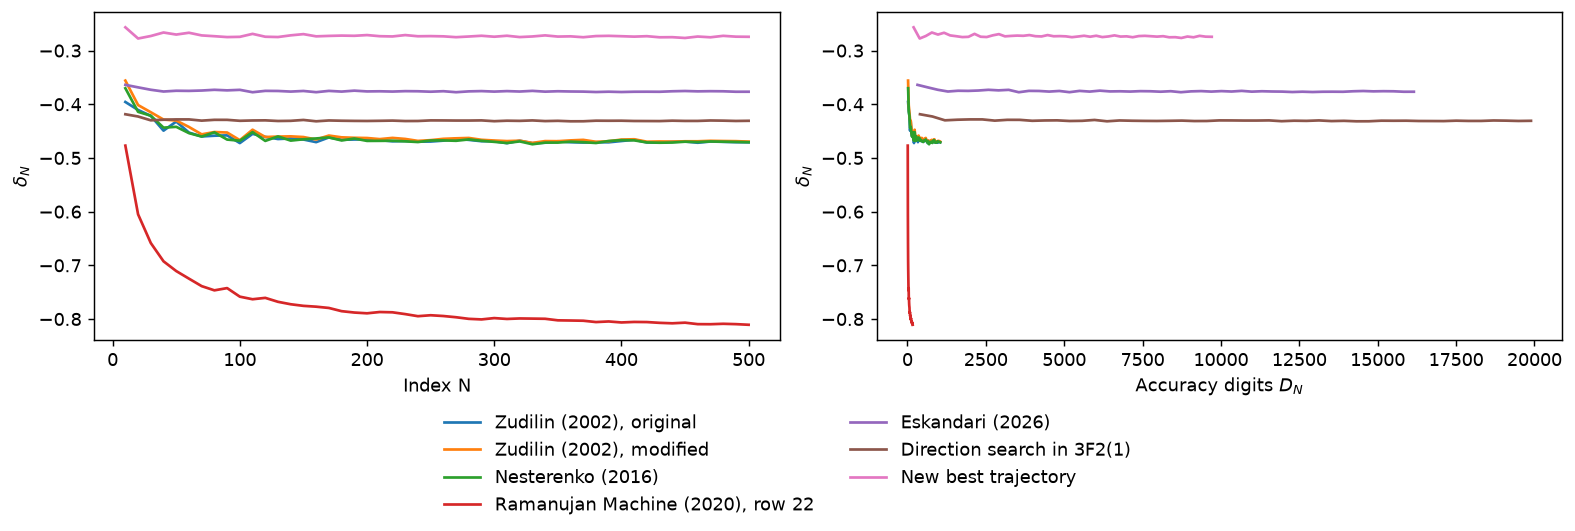

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, (depths, deltas) in results.items():
    axes[0].plot(depths, deltas, label=name)
    axes[1].plot(accuracy[name], deltas)
axes[0].set(xlabel="Index N", ylabel=r"$\delta_N$")
axes[1].set(xlabel=r"Accuracy digits $D_N$", ylabel=r"$\delta_N$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
plt.show()

## Historical overview

Only implemented CMF recoveries are listed. The measured column states the actual final index.

In [22]:
bounds = {
    'Zudilin (2002), original': 'derived $\\liminf\\delta_N\\ge-0.4757268902$',
    'Zudilin (2002), modified': 'Derived $\\liminf\\delta_N\\ge-0.4757268902$',
    'Nesterenko (2016)': '—',
    'Ramanujan Machine (2020), row 22': 'Conjectural infinite-limit identity; exact CMF',
    'Eskandari (2026)': '$\\kappa\\ge0.62$',
    'Direction search in 3F2(1)': '—',
    'New best trajectory': 'Manuscript: $\\delta>-0.295976878$',
}
rows = ["| Construction | Published result | Measured delta |", "|:--|:--|:--|"]
for name, bound in bounds.items():
    if name in results:
        depths, deltas = results[name]
        value = f"{deltas[-1]:.12f} (N = {depths[-1]})"
    else:
        value = "Not computed"
    rows.append(f"| {name} | {bound} | {value} |")
display(Markdown("\n".join(rows)))

| Construction | Published result | Measured delta |
|:--|:--|:--|
| Zudilin (2002), original | derived $\liminf\delta_N\ge-0.4757268902$ | -0.470750239853 (N = 500) |
| Zudilin (2002), modified | Derived $\liminf\delta_N\ge-0.4757268902$ | -0.469520771754 (N = 500) |
| Nesterenko (2016) | — | -0.470736149330 (N = 500) |
| Ramanujan Machine (2020), row 22 | Conjectural infinite-limit identity; exact CMF | -0.810709930648 (N = 500) |
| Eskandari (2026) | $\kappa\ge0.62$ | -0.376639353632 (N = 500) |
| Direction search in 3F2(1) | — | -0.430778908504 (N = 500) |
| New best trajectory | Manuscript: $\delta>-0.295976878$ | -0.274311151264 (N = 500) |